#### Core Concepts {#core-concepts}
The Seaborn Ecosystem
* Seaborn organizes plots into module-level functions and figure-level functions:
* Axes-level functions (draw on a single matplotlib axes):
	* scatterplot(), lineplot(), barplot(), boxplot(), etc.
	* More flexible for complex layouts
	* Returns matplotlib Axes object
* Figure-level functions (manage multiple axes automatically):
	*• relplot(), displot(), catplot(), lmplot(), etc.
	*• Handle subplots automatically

* Return FacetGrid object

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

%matplotlib inline
sns.set_theme() # Set the Seaborn theme for all plots, ensuring a consistent and visually appealing style across the notebook.

#### Seaborn Themes and Context — set_theme(), set_context(), set_palette()
Seaborn provides powerful styling tools that control the overall look of your charts. 

These should typically be called once at the beginning of your script or notebook.

* set_theme():

Controls the overall visual style of plots. Available styles: darkgrid, whitegrid, dark, white, ticks.


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# # Contexts: paper, notebook (default), talk, poster
# sns.set_context('talk')    # Larger fonts — good for presentations
# sns.set_context('poster')  # Largest — for conference posters
# sns.set_context('paper')   # Smallest — for printed documents
sns.set_context('notebook')# Default — for Jupyter notebooks
 
# You can also fine-tune with font_scale
sns.set_context('talk', font_scale=1.2)


In [34]:

 
# Apply a theme globally
sns.set_theme(style='whitegrid')  # Clean white background with grid
 
# Other style options:

# sns.set_theme(style='darkgrid')   # Gray background with white grid
# sns.set_theme(style='ticks')      # White background with axis ticks
sns.set_theme(style='dark')       # Dark background, no grid
# sns.set_theme(style='white')      # Clean white, no grid
 
# Reset to default Matplotlib style
# sns.reset_defaults()


#### set_context()
Controls the scale of plot elements — labels, lines, tick marks. Useful for adapting output to different presentation sizes.


In [ ]:
# Contexts: paper, notebook (default), talk, poster
# sns.set_context('talk')    # Larger fonts — good for presentations
# sns.set_context('poster')  # Largest — for conference posters
sns.set_context('paper')   # Smallest — for printed documents
# sns.set_context('notebook')# Default — for Jupyter notebooks
 
# You can also fine-tune with font_scale
# sns.set_context('talk', font_scale=1.2)


#### set_palette()
Sets the default color palette for all subsequent plots. Seaborn has many beautiful built-in palettes.


In [ ]:
# Qualitative palettes — for categorical data
sns.set_palette('Set2')       # Pastel qualitative
sns.set_palette('tab10')      # Matplotlib default categorical
sns.set_palette('husl')       # Evenly spaced hue colors
 
# Sequential palettes — for numeric data
sns.set_palette('Blues')      # Shades of blue
sns.set_palette('YlOrRd')     # Yellow to Red
 
# Diverging palettes — for data centered around a midpoint
sns.set_palette('RdBu')       # Red to Blue
 
# View a palette
sns.color_palette('Set2', as_cmap=False)
sns.palplot(sns.color_palette('husl', 8))  # Display 8 colors
plt.show()


💡 Tip: Use qualitative palettes for categorical data (gender, city), sequential for ordered numeric data (age, income), and diverging for data with a meaningful center (temperature anomalies, correlation coefficients).

#### Distribution Plots
Distribution plots help you understand the spread and shape of your data. Seaborn provides several functions for this purpose, all of which can be accessed via the unified displot() figure-level wrapper.


#### The Figure-level vs Axes-level Function Distinction
* This is one of the most important concepts in Seaborn. Every plot function in Seaborn falls into one of two categories, and understanding the difference will save you a lot of confusion.
*	Axes-level functions: Axes-level functions: Draw on a specific Matplotlib Axes object. They return an Axes object and can be embedded into multi-plot figures created with plt.subplots(). Examples: histplot(), scatterplot(), boxplot().
*	Figure-level functions: Figure-level functions: Create their own figure (FacetGrid) and manage the entire figure layout. They support faceting via col= and row= parameters. Examples: displot(), catplot(), relplot(), lmplot().


In [3]:
import pandas as pd

tips = pd.DataFrame({
    "total_bill": [16.99, 10.34, 21.01, 23.68, 24.59, 25.29, 8.77, 26.88],
    "tip":        [1.01,  1.66,  3.50,  3.31,  3.61,  4.71,  2.00,  3.12],
    "sex":        ["Female", "Male", "Male", "Male", "Female", "Male", "Male", "Female"],
    "smoker":     ["No", "No", "No", "No", "No", "No", "Yes", "Yes"],
    "day":        ["Sun", "Sun", "Sun", "Sun", "Sun", "Sun", "Sat", "Sat"],
    "time":       ["Dinner", "Dinner", "Dinner", "Dinner", "Dinner", "Dinner", "Lunch", "Dinner"],
    "size":       [2, 3, 3, 2, 4, 4, 2, 4]
})

print(tips.head())


   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


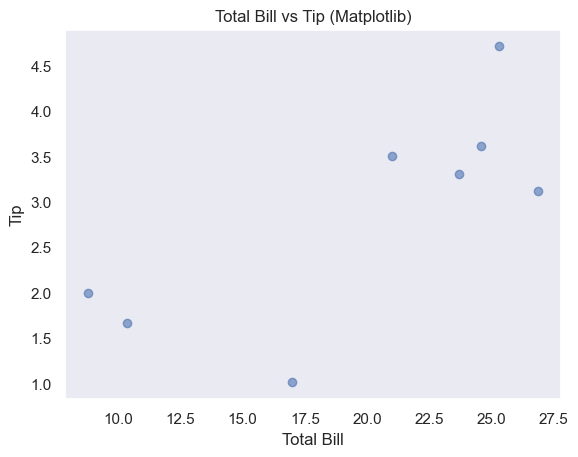

In [37]:
# Matplotlib approach
fig, ax = plt.subplots()
ax.scatter(tips['total_bill'], tips['tip'], alpha=0.6)
ax.set_xlabel('Total Bill')
ax.set_ylabel('Tip')
ax.set_title('Total Bill vs Tip (Matplotlib)')
plt.show()



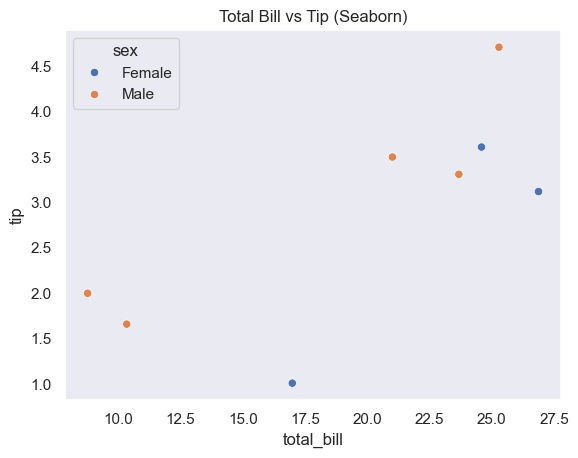

In [38]:
# Seaborn approach
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex')
plt.title('Total Bill vs Tip (Seaborn)')
plt.show()

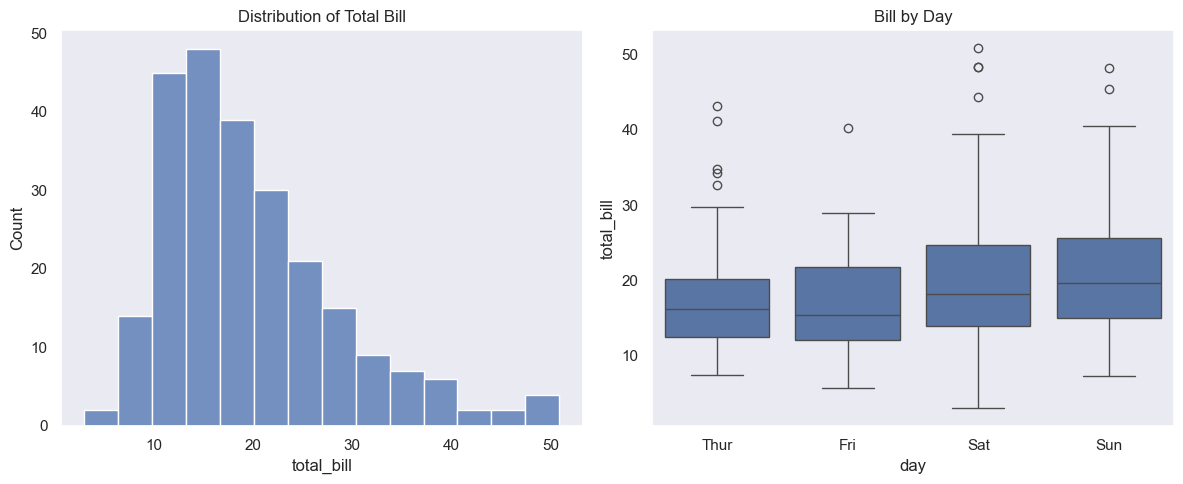

In [ ]:
# ---------- Axes-level example ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
tips = sns.load_dataset('tips')
 
# Each function draws on a specific axes
sns.histplot(data=tips, x='total_bill', ax=axes[0]) # Draw histogram of total_bill on the first subplot (axes[0])
axes[0].set_title('Distribution of Total Bill') # Set title for the first subplot (axes[0])
 
sns.boxplot(data=tips, x='day', y='total_bill', ax=axes[1]) # Draw boxplot of total_bill by day on the second subplot (axes[1])
axes[1].set_title('Bill by Day') # Set title for the second subplot (axes[1])
 
plt.tight_layout()
plt.show()
 



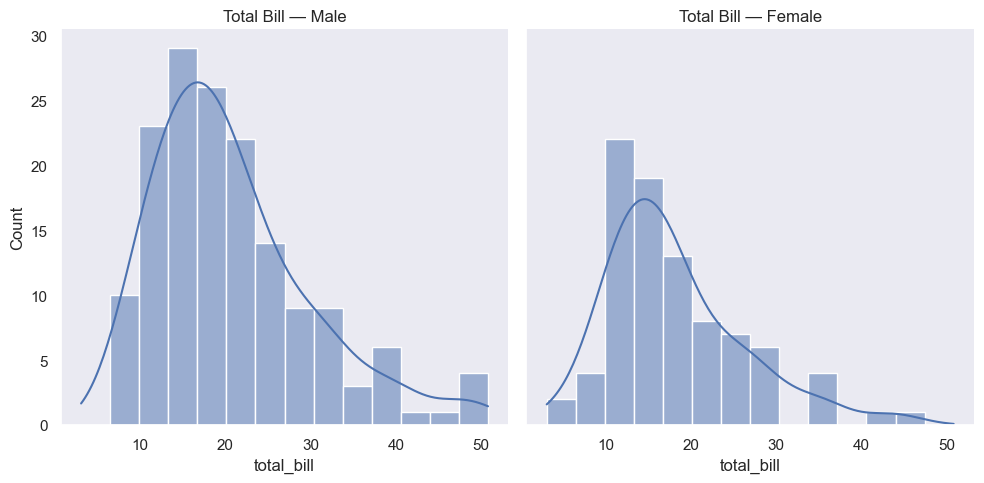

In [ ]:
# ---------- Figure-level example ----------
# displot() creates and manages its own figure
g = sns.displot(data=tips, x='total_bill', col='sex', kde=True) # kernel density estimate (kde=True) adds a smooth curve to the histogram
g.set_titles('Total Bill — {col_name}')  # Use FacetGrid methods to set titles for each subplot
plt.show()

In [ ]:
data = {"Score": [72, 85, 89, 91, 95, 88, 76, 84, 90, 87, 93, 78, 85, 89, 92]}
df = pd.DataFrame(data)

df

#### histogram to show the distribution

In [ ]:
# Create a histogram to show the distribution of exam scores
sns.histplot(df["Score"], bins=8, kde=False) # bins=8 — number of bars in the histogram, kde=False — do not add a kernel density estimate curve
plt.title("Distribution of Exam Scores")  # Set the title of the plot
plt.xlabel("Score")  # Label the x-axis
plt.ylabel("Frequency")  # Label the y-axis
plt.show()  # Display the plot

#### histogram with a KDE (Kernel Density Estimate) curve

In [ ]:
# Create a histogram with a KDE (Kernel Density Estimate) curve to show the distribution of exam scores
sns.histplot(df["Score"], bins=8, kde=True, color="skyblue")
plt.title("Distribution of Exam Scores with KDE Curve")  # Set the title of the plot
plt.xlabel("Score")  # Label the x-axis
plt.ylabel("Density")  # Label the y-axis
plt.show()  # Display the plot

#### box plot to show the distribution

In [ ]:
# Create a box plot to show the distribution of exam scores
sns.boxplot(x=df["Score"], color="lightgreen")
plt.title("Exam Score Distribution (Box Plot)")  # Set the title of the plot
plt.xlabel("Score")  # Label the x-axis
plt.show()  # Display the plot

#### violin plot to show the distribution

In [ ]:
# Create a violin plot to show the distribution of exam scores
sns.violinplot(x=df["Score"], color="orchid")
plt.title("Exam Score Distribution (Violin Plot)")  # Set the title of the plot
plt.xlabel("Score")  # Label the x-axis
plt.show()  # Display the plot

#### kdeplot() — Univariate and Bivariate Density

KDE (Kernel Density Estimate) plots show a smooth probability density curve fitted to the data. Unlike histograms, KDE plots are continuous and don't depend on bin width choices.


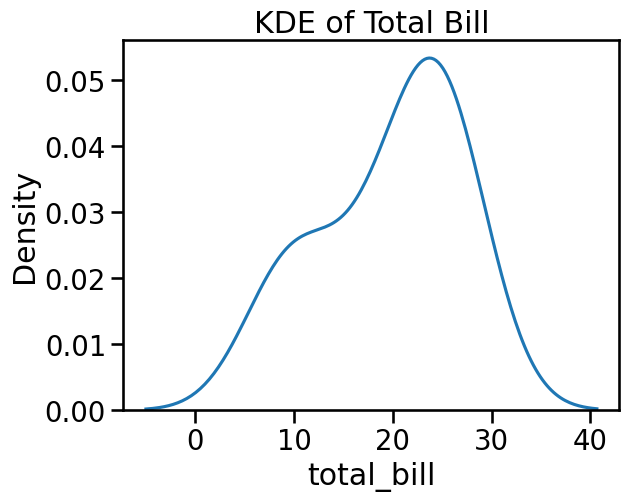

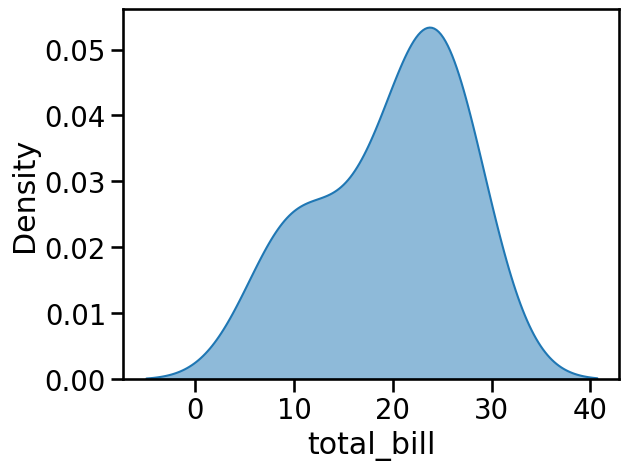

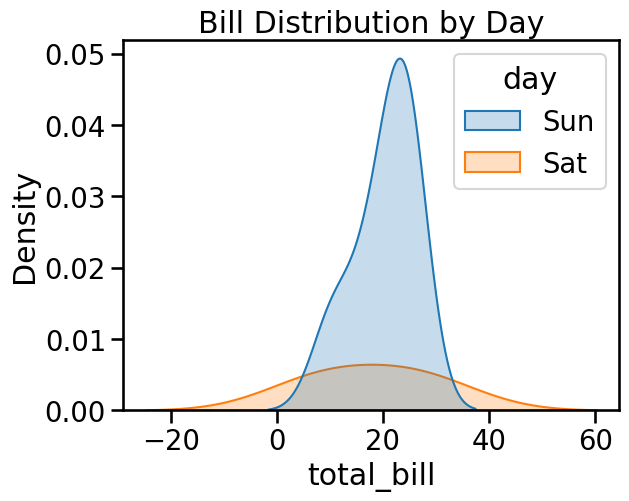

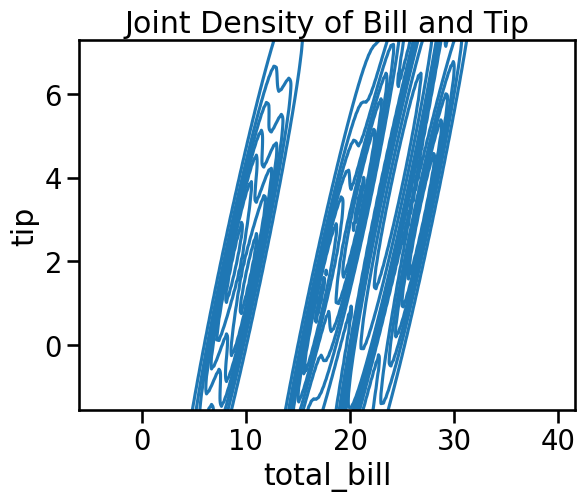

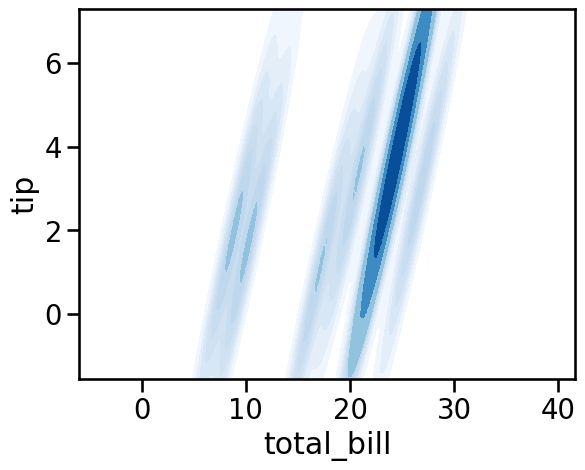

In [5]:
# Univariate KDE — one variable
sns.kdeplot(data=tips, x='total_bill')
plt.title('KDE of Total Bill')
plt.show()
 
# KDE with shading (fill=True)
sns.kdeplot(data=tips, x='total_bill', fill=True, alpha=0.5)
plt.show()
 
# Multiple groups with hue
sns.kdeplot(data=tips, x='total_bill', hue='day', fill=True)
plt.title('Bill Distribution by Day')
plt.show()
 
# Bivariate KDE — two variables (shows joint density)
sns.kdeplot(data=tips, x='total_bill', y='tip')
plt.title('Joint Density of Bill and Tip')
plt.show()
 
# Bivariate with filled contours
sns.kdeplot(data=tips, x='total_bill', y='tip',
            fill=True, cmap='Blues')
plt.show()


#### ecdfplot() — Empirical Cumulative Distribution

An ECDF (Empirical Cumulative Distribution Function) plot shows what percentage of the data falls below each value. It is extremely useful for comparing distributions across groups.


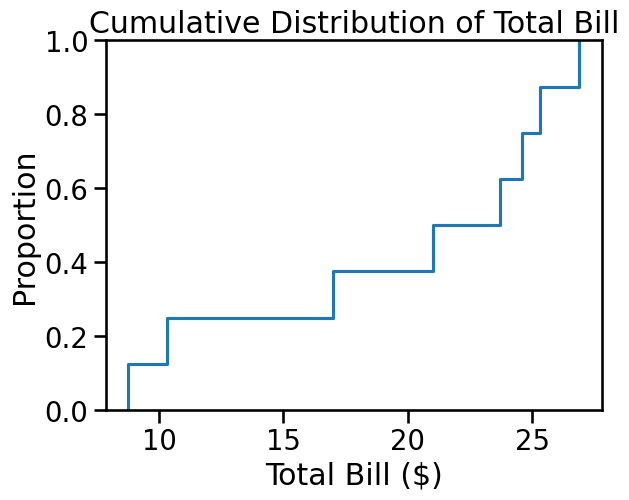

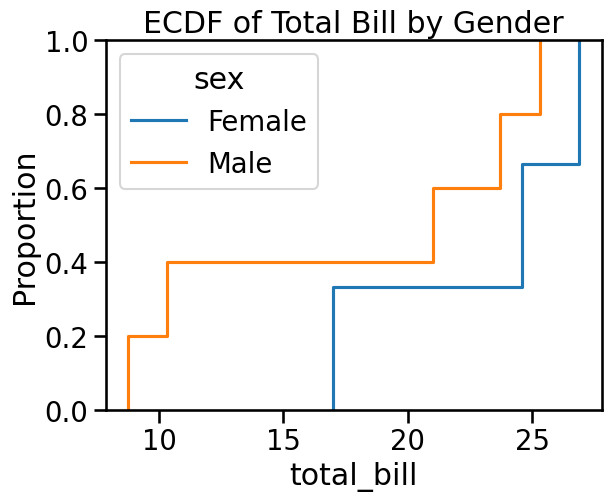

In [6]:
# Basic ECDF
sns.ecdfplot(data=tips, x='total_bill')
plt.title('Cumulative Distribution of Total Bill')
plt.xlabel('Total Bill ($)')
plt.ylabel('Proportion')
plt.show()
 
# Compare groups — very powerful for quick comparison
sns.ecdfplot(data=tips, x='total_bill', hue='sex')
plt.title('ECDF of Total Bill by Gender')
plt.show()
 
# Reading the chart: at x=20, the y-value tells you
# what fraction of bills were LESS THAN $20


#### rugplot() — Marginal Ticks

A rug plot places a small tick mark on the axis for each individual data point. It is rarely used alone but is very effective when layered on top of histograms or KDE plots to show the actual data locations.


In [ ]:
# Rugplot alone — rarely useful by itself
sns.rugplot(data=tips, x='total_bill')
plt.show()
 
# Most useful: layered with KDE
sns.kdeplot(data=tips, x='total_bill', fill=True, alpha=0.4)
sns.rugplot(data=tips, x='total_bill', color='red', alpha=0.5)
plt.title('KDE + Rug (showing individual data points)')
plt.show()


#### displot() — Figure-level Wrapper for All Distribution Plots
displot() is the figure-level interface that can produce histograms, KDE plots, and ECDF plots. Its main advantage is built-in faceting using col= and row= parameters.


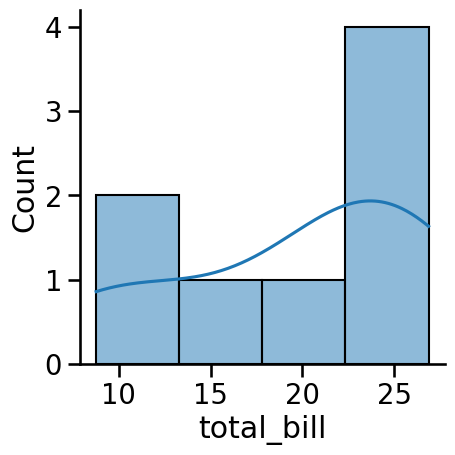

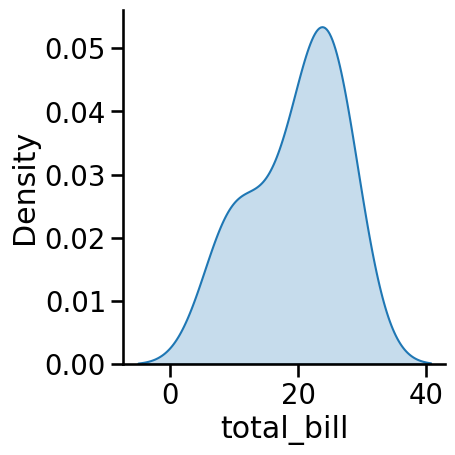

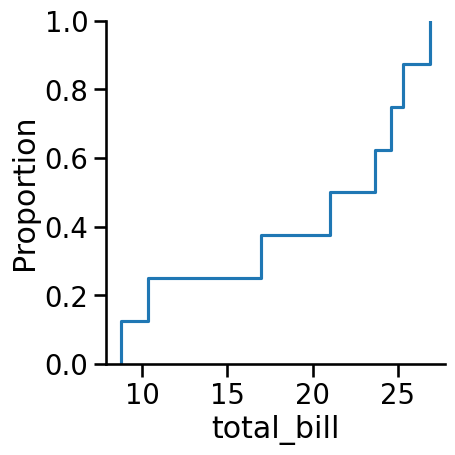

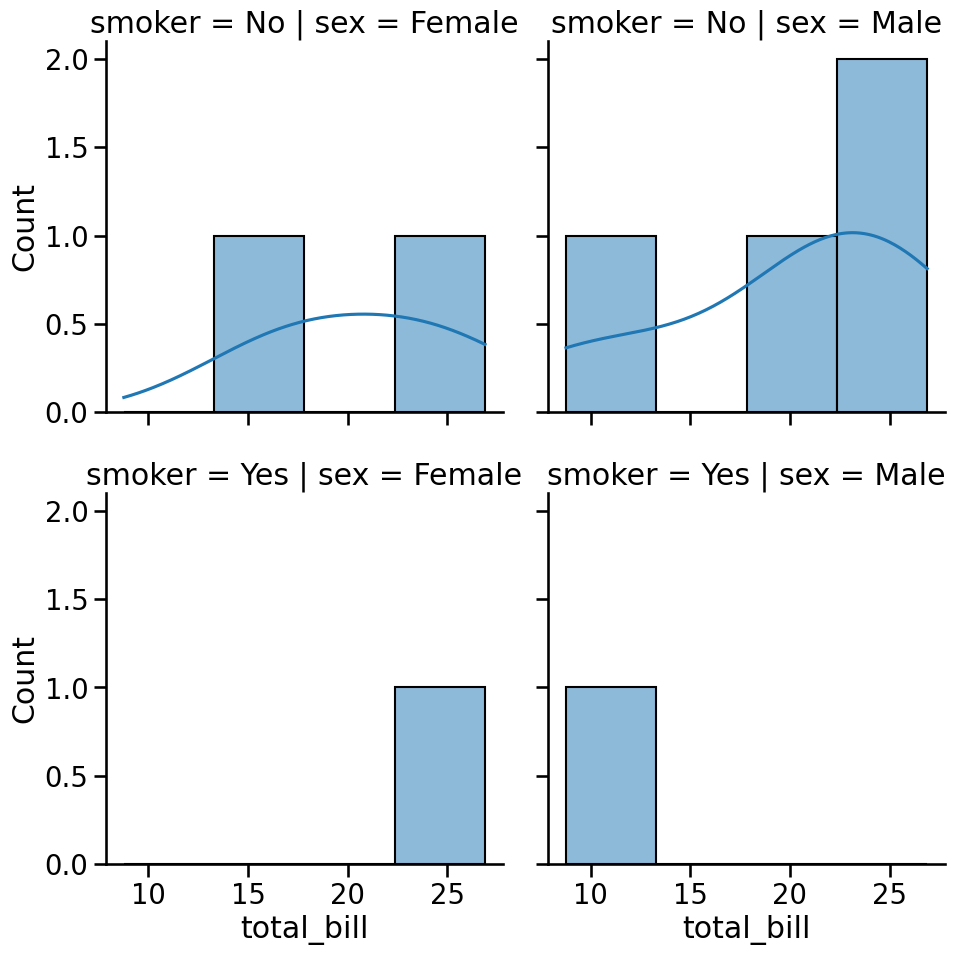

In [7]:
# Histogram using displot
sns.displot(data=tips, x='total_bill', kind='hist', kde=True)
plt.show()
 
# KDE using displot
sns.displot(data=tips, x='total_bill', kind='kde', fill=True)
plt.show()
 
# ECDF using displot
sns.displot(data=tips, x='total_bill', kind='ecdf')
plt.show()
 
# FACETING — split into panels by a category
sns.displot(data=tips, x='total_bill',
            col='sex',         # One column per gender
            row='smoker',      # One row per smoker status
            kind='hist',
            kde=True)
plt.show()
# This creates a 2x2 grid of panels — very powerful!


In [ ]:
data = {
    "Hours_Studied": [5, 8, 7, 6, 9, 4, 10, 8, 6, 7],
    "Score": [75, 88, 85, 80, 90, 70, 95, 89, 78, 84],
    "Projects_Completed": [2, 4, 3, 3, 5, 2, 5, 4, 3, 3],
    "Attendance_Rate": [0.9, 0.95, 0.93, 0.88, 0.97, 0.85, 0.98, 0.94, 0.9, 0.92]
}

df = pd.DataFrame(data)

df.head()

In [ ]:
# Calculate the correlation matrix for the DataFrame
corr = df.corr()

corr

In [ ]:
# Create a heatmap to visualize the correlation matrix
sns.heatmap(corr)
plt.title("Correlation Heatmap")  # Set the title of the heatmap
plt.show()  # Display the heatmap

In [ ]:
# Create a heatmap with annotations and a color map to visualize the correlation matrix
sns.heatmap(corr, annot=True, cmap="YlGnBu")
plt.title("Correlation Heatmap with Annotations")  # Set the title of the heatmap
plt.show()  # Display the heatmap

In [ ]:
# Create a heatmap with a different color map to visualize the correlation matrix
sns.heatmap(corr, cmap="coolwarm")
plt.title("Correlation Heatmap (Coolwarm)")  # Set the title of the heatmap
plt.show()  # Display the heatmap

In [ ]:
# Create a heatmap with a mask to show only the lower triangle of the correlation matrix
import numpy as np  # Import numpy for creating the mask
mask = np.triu(np.ones_like(corr, dtype=bool))  # Create a mask for the upper triangle
sns.heatmap(corr, mask=mask, cmap="coolwarm")
plt.title("Correlation Heatmap (Lower Triangle)")  # Set the title of the heatmap
plt.show()  # Display the heatmap

In [ ]:
# Load the 'tips' dataset from seaborn's built-in datasets
tips = sns.load_dataset('tips')
# Display the first few rows of the dataset
tips.head()

In [ ]:
fig, ax = plt.subplots(1, 2)

In [ ]:
# Create a figure with two subplots side by side
fig, ax = plt.subplots(1, 2)

# Plot a histogram of the 'total_bill' column in the first subplot
sns.histplot(tips["total_bill"], ax=ax[0], color="skyblue")
ax[0].set_title("Total Bill Distribution")  # Set the title for the first subplot

# Plot a boxplot of the 'tip' column in the second subplot
sns.boxplot(y=tips["tip"], ax=ax[1], color="lightgreen")
ax[1].set_title("Tip Amounts")  # Set the title for the second subplot
plt.show()  # Display the subplots

In [ ]:
# Create a figure with a 2x2 grid of subplots and set the overall figure size
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

In [ ]:
# Create a figure with a 2x2 grid of subplots and set the overall figure size
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

# Plot a histogram of 'total_bill' in the top-left subplot
sns.histplot(tips["total_bill"], ax=ax[0, 0], color="skyblue")
ax[0, 0].set_title("Total Bill")  # Set the title for the top-left subplot

# Plot a boxplot of 'tip' in the top-right subplot
sns.boxplot(y=tips["tip"], ax=ax[0, 1], color="lightgreen")
ax[0, 1].set_title("Tip")  # Set the title for the top-right subplot

# Plot a scatterplot of 'total_bill' vs 'tip' in the bottom-left subplot
sns.scatterplot(x="total_bill", y="tip", data=tips, ax=ax[1, 0], color="orchid")
ax[1, 0].set_title("Bill vs Tip")  # Set the title for the bottom-left subplot

# Plot a barplot of average 'total_bill' by 'day' in the bottom-right subplot
sns.barplot(x="day", y="total_bill", data=tips, ax=ax[1, 1], color="coral")
ax[1, 1].set_title("Average Bill by Day")  # Set the title for the bottom-right subplot

plt.tight_layout()  # Adjust subplot spacing to prevent overlap
plt.show()  # Display all subplots

In [ ]:
# Create a figure with two subplots side by side, sharing the y-axis, and set the figure size
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(8, 4))
# Plot a histogram of 'total_bill' for male customers in the first subplot
sns.histplot(tips[tips["sex"] == "Male"]["total_bill"], ax=ax[0], color="steelblue")
ax[0].set_title("Male Customers")  # Set the title for the first subplot

# Plot a histogram of 'total_bill' for female customers in the second subplot
sns.histplot(tips[tips["sex"] == "Female"]["total_bill"], ax=ax[1], color="plum")
ax[1].set_title("Female Customers")  # Set the title for the second subplot

plt.suptitle("Total Bill Distribution by Gender", fontsize=14)  # Set the overall figure title
plt.tight_layout()  # Adjust subplot spacing to prevent overlap
plt.show()  # Display the subplots

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
sns.histplot(tips["total_bill"], ax=ax[0], color="skyblue")
ax[0].set_title("Total Bill")

sns.histplot(tips["tip"], ax=ax[1], color="lightgreen")
ax[1].set_title("Tip")

plt.subplots_adjust(wspace=0.4)  # increase horizontal space between plots
plt.show()

In [ ]:
# Create a figure with two subplots side by side and set the figure size
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# Plot a histogram of 'total_bill' in the first subplot
sns.histplot(tips["total_bill"], ax=ax[0], color="skyblue")
ax[0].set_title("Total Bill")  # Set the title for the first subplot

# Plot a histogram of 'tip' in the second subplot
sns.histplot(tips["tip"], ax=ax[1], color="lightgreen")
ax[1].set_title("Tip")  # Set the title for the second subplot

plt.subplots_adjust(wspace=0.4)  # Increase horizontal space between plots
plt.show()  # Display the subplots

histplot() — Bins, KDE Overlay, Hue
histplot() creates a histogram — a bar chart that shows the frequency of values within equal-width intervals (bins). It is the most fundamental distribution visualization tool.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
 
# Load dataset
tips = sns.load_dataset('tips')
 
# Basic histogram
sns.histplot(data=tips, x='total_bill')
plt.title('Distribution of Total Bill')
plt.show()
 
# Control number of bins
sns.histplot(data=tips, x='total_bill', bins=20)
plt.show()
 
# Add KDE (Kernel Density Estimate) overlay
sns.histplot(data=tips, x='total_bill', bins=20, kde=True)
plt.title('Histogram with KDE Overlay')
plt.show()
 
# Separate by category using hue
sns.histplot(data=tips, x='total_bill', hue='sex', bins=20, kde=True)
plt.title('Total Bill Distribution by Gender')
plt.show()
 
# Multiple='stack' to stack bars instead of overlapping
sns.histplot(data=tips, x='total_bill', hue='sex',
             multiple='stack', bins=20)
plt.show()


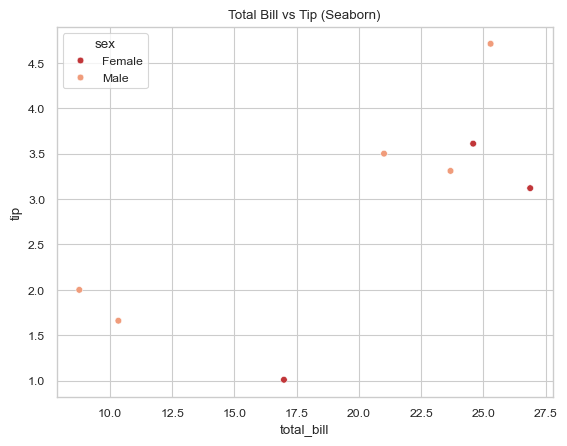

In [19]:
tips = pd.read_csv("../data/tips.csv")

# Seaborn approach
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex')
plt.title('Total Bill vs Tip (Seaborn)')
plt.show()

In [10]:
import numpy as np
import pandas as pd
# Rename the function to 'order'
def order(n=50, seed=1):
    rng = np.random.default_rng(seed)

    df = pd.DataFrame({
        "order_id": [f"ORD{1000+i}" for i in range(n)],
        "order_date": pd.to_datetime("2025-01-01") +
                      pd.to_timedelta(rng.integers(0, 90, size=n), unit="D"),

        "city": rng.choice(
            ["Bengaluru", "Hyderabad", "Chennai", "Mumbai", "Delhi"],
            size=n
        ),

        "customer_type": rng.choice(
            ["New", "Returning", "Loyal"],
            size=n,
            p=[0.35, 0.40, 0.25]
        ),

        "category": rng.choice(
            ["Electronics", "Fashion", "Grocery", "Home"],
            size=n
        ),

        "quantity": rng.integers(1, 5, size=n),

        "unit_price": rng.integers(200, 5000, size=n),

        "discount_pct": rng.choice(
            [0, 5, 10, 15, 20],
            size=n,
            p=[0.30, 0.25, 0.20, 0.15, 0.10]
        ),

        "payment_method": rng.choice(
            ["UPI", "Card", "COD", "Wallet"],
            size=n
        ),

        "delivery_days": rng.integers(1, 8, size=n),

        "order_status": rng.choice(
            ["Delivered", "Cancelled", "Returned"],
            size=n,
            p=[0.78, 0.12, 0.10]
        ),

        "rating": rng.choice(
            [1, 2, 3, 4, 5, None],
            size=n,
            p=[0.05, 0.10, 0.15, 0.35, 0.25, 0.10]
        ),

        "coupon_used": rng.choice([0, 1], size=n, p=[0.6, 0.4])
    })

    # Derived fields (good for training)
    df["gross_amount"] = df["quantity"] * df["unit_price"]
    df["discount_amount"] = (df["gross_amount"] * df["discount_pct"] / 100).round(2)
    df["net_amount"] = df["gross_amount"] - df["discount_amount"]

    df["delivery_delay_flag"] = df["delivery_days"] > 5

    return df


# Example usage
df = order()
df.head(10)

,order_id,order_date,city,customer_type,category,quantity,unit_price,discount_pct,payment_method,delivery_days,order_status,rating,coupon_used,gross_amount,discount_amount,net_amount,delivery_delay_flag
0,ORD1000,2025-02-12,Bengaluru,Returning,Grocery,3,621,5,COD,1,Delivered,2,0,1863,93.15,1769.85,False
1,ORD1001,2025-02-16,Mumbai,Loyal,Grocery,2,4831,0,COD,5,Returned,4,0,9662,0.00,9662.00,False
2,ORD1002,2025-03-09,Hyderabad,New,Electronics,1,2552,5,Wallet,4,Delivered,1,1,2552,127.60,2424.40,False
3,ORD1003,2025-03-27,Chennai,Loyal,Fashion,1,2127,20,Card,1,Delivered,2,1,2127,425.40,1701.60,False
4,ORD1004,2025-01-04,Delhi,New,Home,1,3704,0,Card,1,Delivered,2,1,3704,0.00,3704.00,False
5,ORD1005,2025-01-13,Hyderabad,New,Home,1,1617,10,UPI,4,Delivered,3,0,1617,161.70,1455.30,False
6,ORD1006,2025-03-16,Mumbai,Loyal,Fashion,2,3258,5,UPI,6,Delivered,4,1,6516,325.80,6190.20,True
7,ORD1007,2025-03-27,Bengaluru,Loyal,Grocery,2,4265,0,UPI,5,Delivered,5,1,8530,0.00,8530.00,False
8,ORD1008,2025-01-23,Hyderabad,Loyal,Electronics,1,4055,20,Card,2,Delivered,3,1,4055,811.00,3244.00,False
9,ORD1009,2025-01-29,Delhi,Returning,Home,2,797,0,UPI,2,Delivered,3,0,1594,0.00,1594.00,False


city
Bengaluru    7320.407143
Chennai      8660.896429
Delhi        7972.194444
Hyderabad    4480.827778
Mumbai       7807.031818
Name: net_amount, dtype: float64


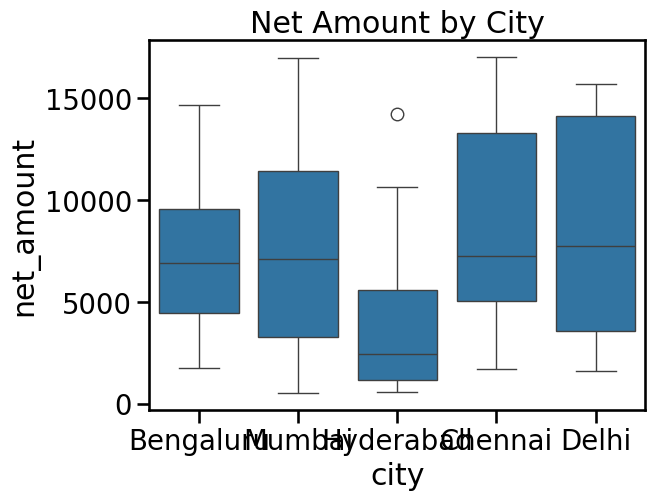

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

#print net ammount per city
print(df.groupby('city')['net_amount'].mean())

# Boxplot: Net Amount by City
sns.boxplot(data=df, x='city', y='net_amount')
plt.title('Net Amount by City')
plt.show()


city       customer_type
Bengaluru  Loyal             7711.325000
           New              10524.800000
           Returning         6323.850000
Chennai    Loyal             7196.025000
           New              10260.878571
           Returning         6880.766667
Delhi      Loyal             7715.200000
           New               9260.837500
           Returning         6747.800000
Hyderabad  Loyal             4992.700000
           New               1662.150000
           Returning         7685.100000
Mumbai     Loyal             8421.550000
           New               5716.583333
           Returning         8760.350000
Name: net_amount, dtype: float64


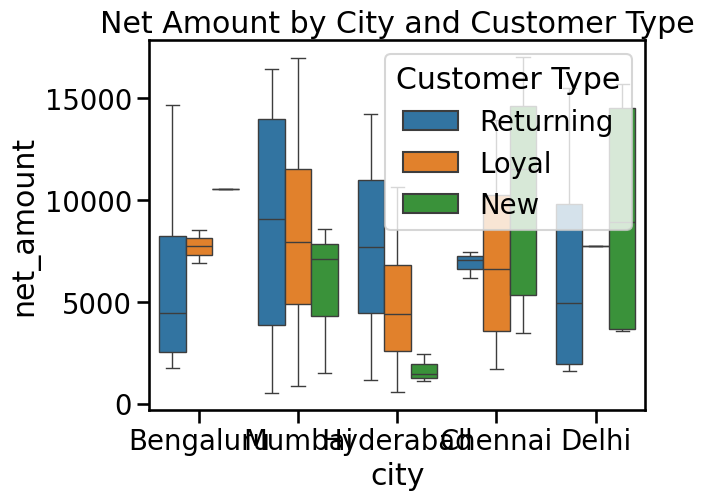

In [18]:
# print Net Amount by City and Customer Type
print(df.groupby(['city', 'customer_type'])['net_amount'].mean())

# Boxplot: Net Amount by City and Customer Type
sns.boxplot(data=df, x='city', y='net_amount', hue='customer_type')
plt.title('Net Amount by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()


city
Bengaluru    7320.407143
Chennai      8660.896429
Delhi        7972.194444
Hyderabad    4480.827778
Mumbai       7807.031818
Name: net_amount, dtype: float64


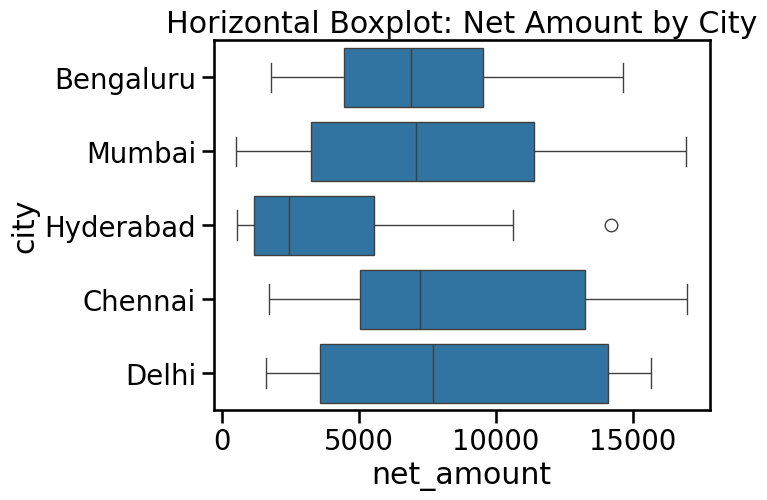

In [19]:
# print Net Amount by City
print(df.groupby('city')['net_amount'].mean())

# Horizontal boxplot: useful with many categories
sns.boxplot(data=df, y='city', x='net_amount')
plt.title('Horizontal Boxplot: Net Amount by City')
plt.show()


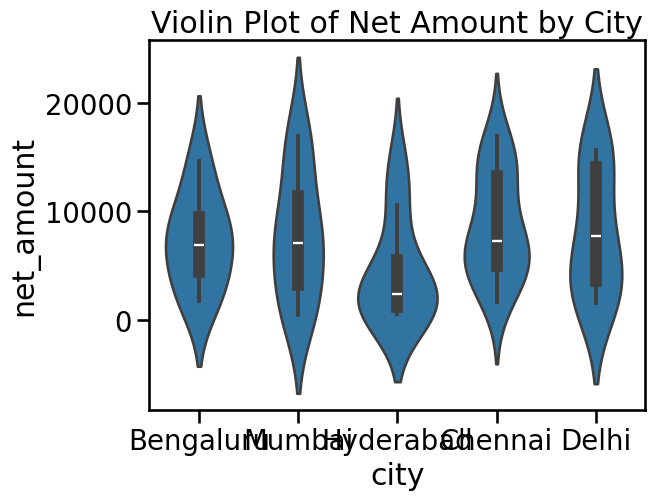

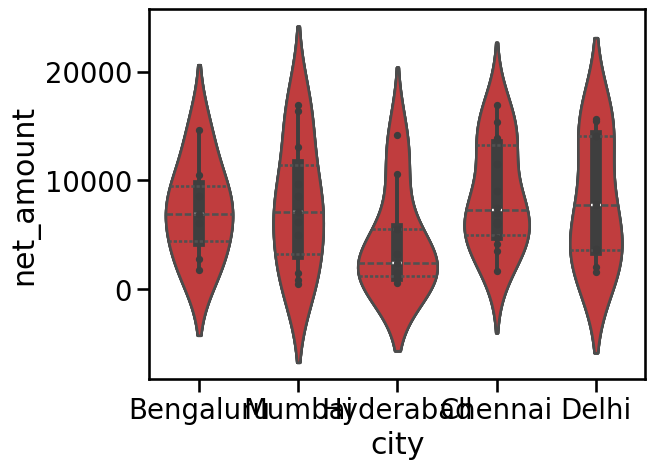

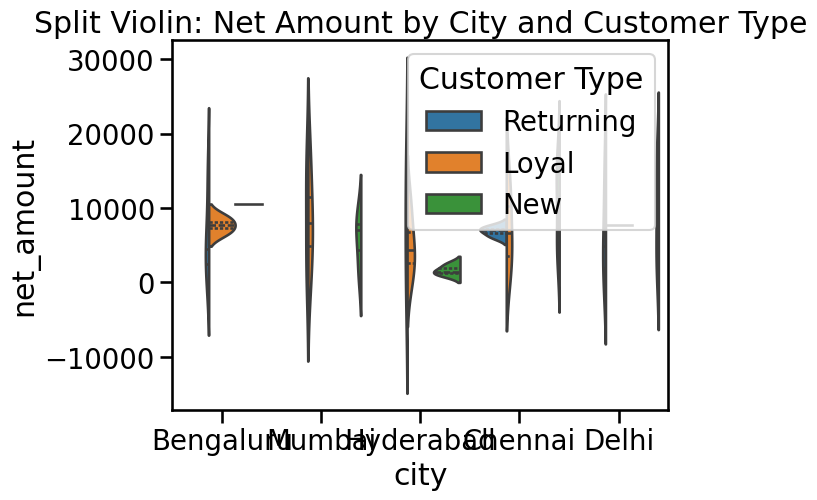

In [22]:
# Violin plot examples using the 'df' DataFrame

# Basic violin plot: Net Amount by City
sns.violinplot(data=df, x='city', y='net_amount')
plt.title('Violin Plot of Net Amount by City')
plt.show()

# Show different inner options for violin plots
sns.violinplot(data=df, x='city', y='net_amount', inner='box')       # Show box plot inside (default)
sns.violinplot(data=df, x='city', y='net_amount', inner='quartile')  # Show Q1, median, Q3 lines
sns.violinplot(data=df, x='city', y='net_amount', inner='point')     # Show individual data points
sns.violinplot(data=df, x='city', y='net_amount', inner=None)        # Clean violin, no inner marks
plt.show()

# Split violins — compare customer types within each city
sns.violinplot(data=df, x='city', y='net_amount', hue='customer_type', split=True, inner='quartile')
plt.title('Split Violin: Net Amount by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()
# Split=True shows each half of the violin for one group

#### Bar Plot — barplot()

A bar plot shows the estimated central tendency (by default, the mean) of a numeric variable for each category, along with a confidence interval (error bar) that indicates estimation uncertainty.


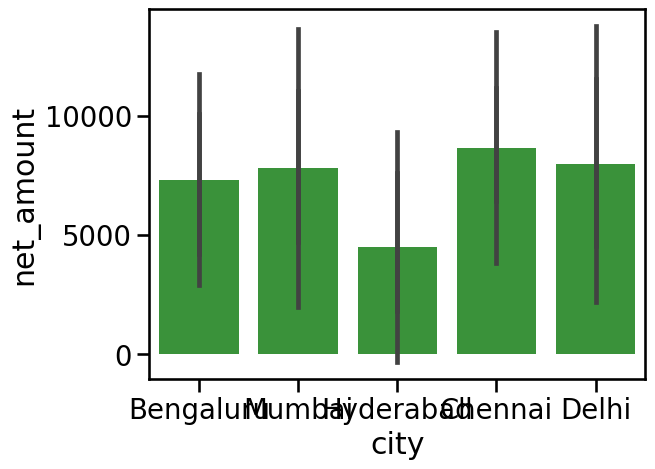

In [24]:
# The error bar (thin line at top) shows 95% confidence interval
 # This is NOT the standard deviation — it's the uncertainty of the mean

# Control the error bar type
sns.barplot(data=df, x='city', y='net_amount', errorbar='sd')       # Standard deviation
sns.barplot(data=df, x='city', y='net_amount', errorbar=('ci', 95)) # 95% confidence interval (default)
sns.barplot(data=df, x='city', y='net_amount', errorbar=None)       # No error bar
plt.show()

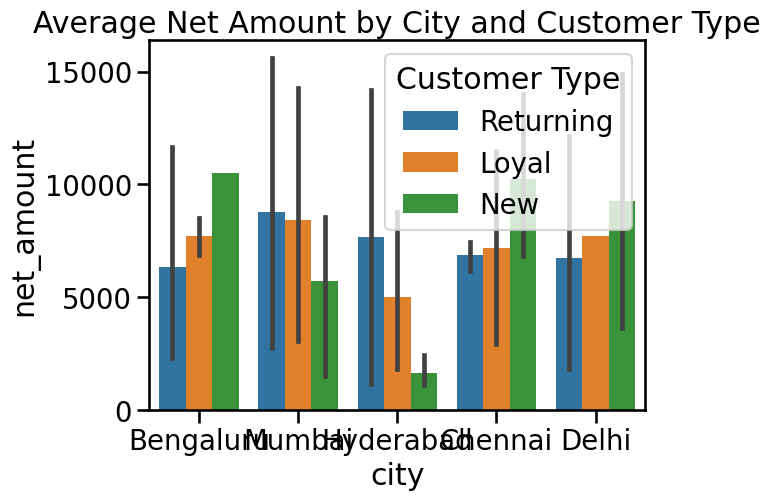

In [26]:
# Add hue for grouping by customer type
sns.barplot(data=df, x='city', y='net_amount', hue='customer_type')
plt.title('Average Net Amount by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()

#### Strip Plot — stripplot()

A strip plot shows individual data points for each category. Unlike aggregated plots, you see every single observation. It is very useful for small-to-medium datasets where you want to see the raw data.


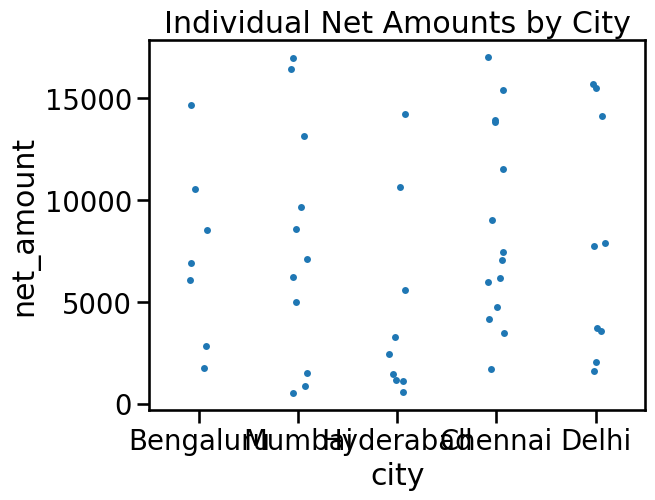

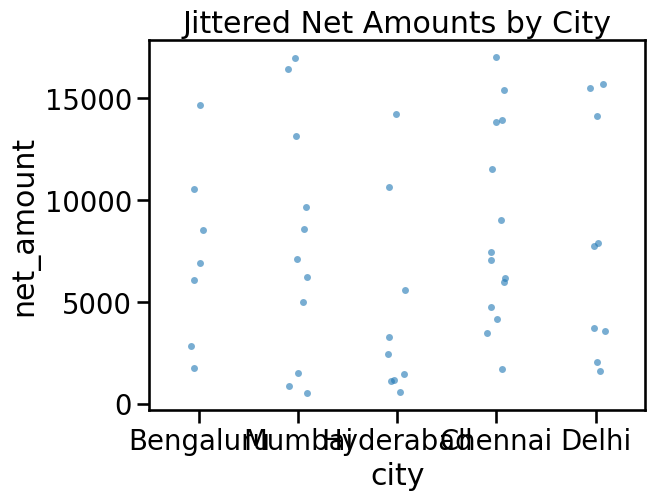

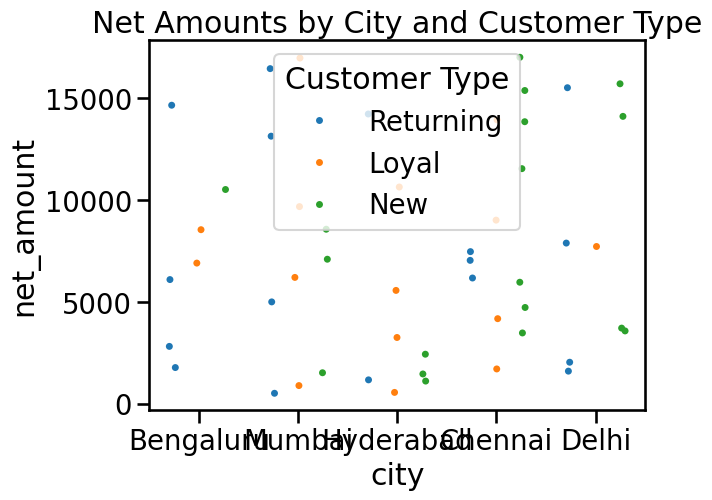

In [27]:
# Basic strip plot: Net Amount by City
sns.stripplot(data=df, x='city', y='net_amount')
plt.title('Individual Net Amounts by City')
plt.show()

# Add jitter to prevent overplotting
sns.stripplot(data=df, x='city', y='net_amount', jitter=True, alpha=0.6)
plt.title('Jittered Net Amounts by City')
plt.show()

# Color by customer type
sns.stripplot(data=df, x='city', y='net_amount', hue='customer_type', jitter=True, dodge=True)
# dodge=True separates points by customer type group
plt.title('Net Amounts by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()

#### Swarm Plot — swarmplot()

A swarm plot is like a strip plot, but points are arranged so they never overlap. Each point is offset to avoid collisions while keeping the overall position accurate. It provides both individual point visibility and a density impression.


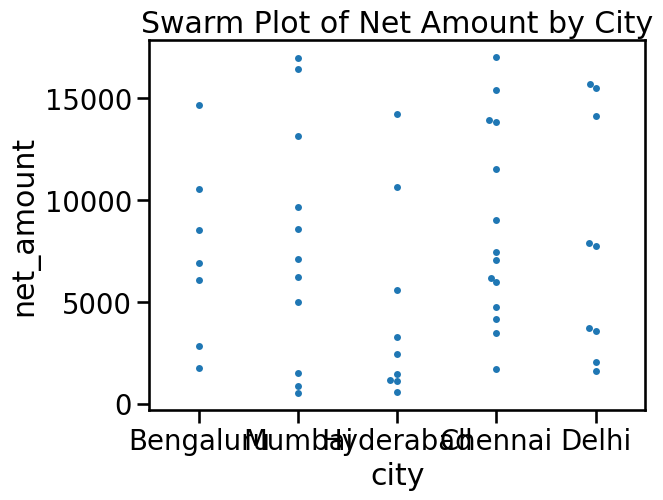

In [28]:
# Basic swarm plot: Net Amount by City
sns.swarmplot(data=df, x='city', y='net_amount')
plt.title('Swarm Plot of Net Amount by City')
plt.show()



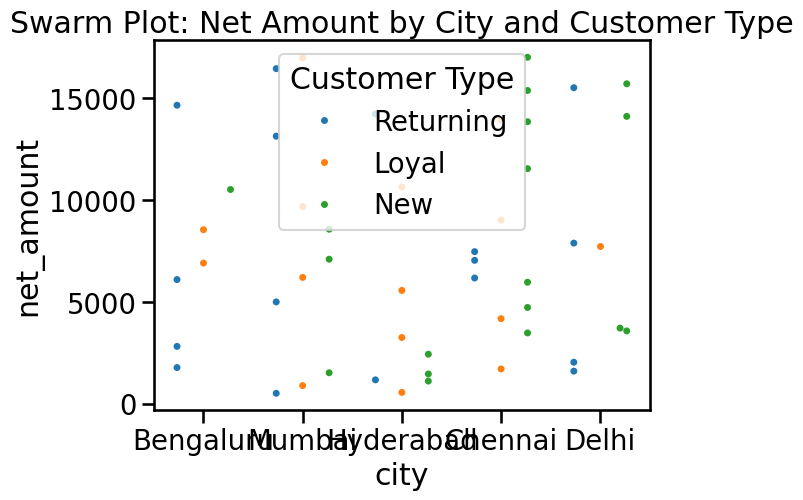

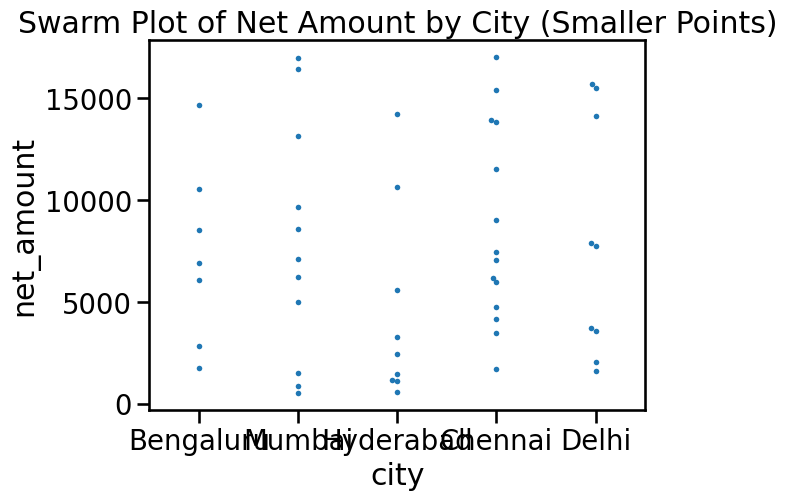

In [29]:
# With hue grouping by customer type
sns.swarmplot(data=df, x='city', y='net_amount', hue='customer_type', dodge=True)
plt.title('Swarm Plot: Net Amount by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()

# Control point size
sns.swarmplot(data=df, x='city', y='net_amount', size=4)
plt.title('Swarm Plot of Net Amount by City (Smaller Points)')
plt.show()

# IMPORTANT: Swarm plots can be SLOW with large datasets
 # They work best with fewer than ~1000 data points

Point Plot — pointplot()
A point plot shows point estimates (default: mean) with confidence intervals connected by lines across categories. It is ideal for showing trends and interactions between categorical variables.


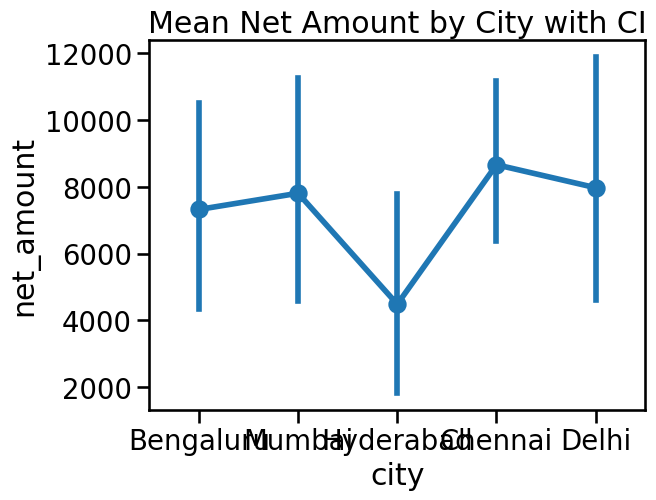

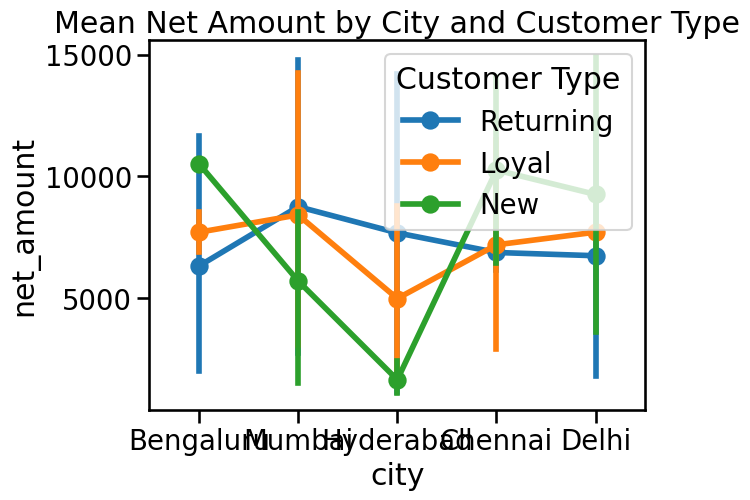

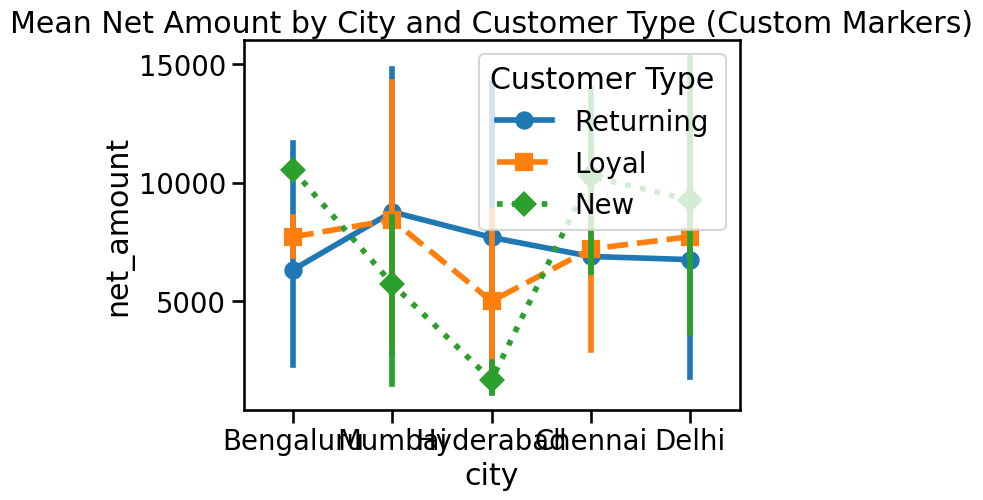

In [30]:
# Basic point plot: Mean Net Amount by City
sns.pointplot(data=df, x='city', y='net_amount')
plt.title('Mean Net Amount by City with CI')
plt.show()

# With hue — shows interaction between two categorical variables (city and customer type)
sns.pointplot(data=df, x='city', y='net_amount', hue='customer_type')
plt.title('Mean Net Amount by City and Customer Type')
plt.legend(title='Customer Type')
plt.show()

# The lines connecting points reveal whether the trend is consistent
 # across groups. If lines are parallel, no interaction effect.
 # If lines cross, there IS an interaction.

# Customize markers and line style
sns.pointplot(data=df, x='city', y='net_amount', hue='customer_type',
              markers=['o', 's', 'D'],       # Circle, square, diamond markers
              linestyles=['-', '--', ':'])   # Solid, dashed, dotted lines
plt.title('Mean Net Amount by City and Customer Type (Custom Markers)')
plt.legend(title='Customer Type')
plt.show()

Combining Plots — Overlaying Plots for Richer Insight
One of the most powerful techniques in Seaborn is overlaying multiple plot types on the same axes. A very common and highly informative combination is placing a strip plot or swarm plot on top of a boxplot or violin plot.


C:\Users\vikas.karanth\AppData\Local\Temp\ipykernel_19376\2746166472.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='city', y='net_amount',


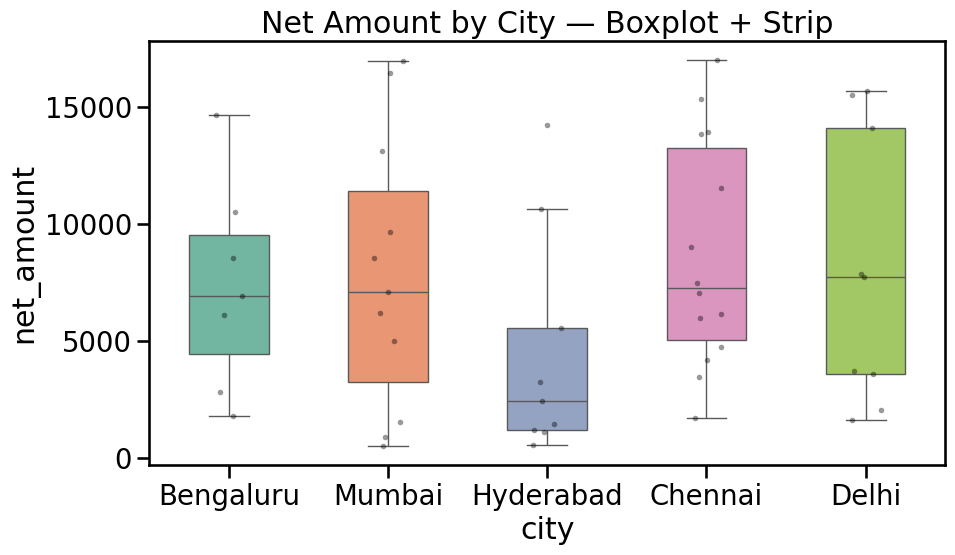

C:\Users\vikas.karanth\AppData\Local\Temp\ipykernel_19376\2746166472.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='city', y='net_amount',


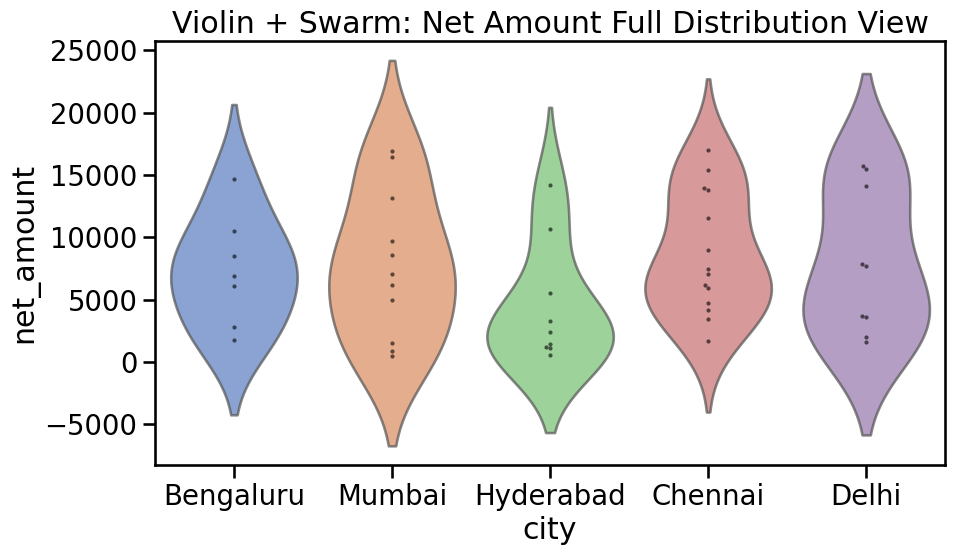

In [31]:
# ---- Boxplot + Stripplot for Net Amount by City ----
fig, ax = plt.subplots(figsize=(10, 6))

# Draw boxplot first (as background)
sns.boxplot(data=df, x='city', y='net_amount',
            palette='Set2', width=0.5, ax=ax,
            flierprops=dict(marker='', alpha=0))  # Hide outlier dots

# Overlay strip plot with individual points
sns.stripplot(data=df, x='city', y='net_amount',
              color='black', alpha=0.4, size=4,
              jitter=True, ax=ax)

ax.set_title('Net Amount by City — Boxplot + Strip')
plt.tight_layout()
plt.show()

# ---- Violinplot + Swarmplot for Net Amount by City ----
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(data=df, x='city', y='net_amount',
               inner=None, palette='muted', alpha=0.7, ax=ax)

sns.swarmplot(data=df, x='city', y='net_amount',
              color='black', alpha=0.6, size=3, ax=ax)

ax.set_title('Violin + Swarm: Net Amount Full Distribution View')
plt.tight_layout()
plt.show()